In [27]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

In [28]:
# ---------------------------------------------------------------- environment
ENV = "TEST"                 # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step1") # name this how you wish

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "EV charging systems"
SECTOR_CPC_PREFIXES = (      # a family is in the sector if any of its CPC symbols starts with one of these
    "B60L 53/",
    "B60L 55/",
    #"H02J 7/",
    "Y02T 90/",
    #------------
    #"H01B",
    #"H01F",
    #"H01H",
    #"H02", 
    #"H02B",
    #"H02J",
    #"H02M",
)
SECTOR_KEYWORDS = (          # optional: OR-ed with the CPC codes, searched in titles and abstracts
    # "wave energy converter",
)

# ---------------------------------------------------------------- time window, you can choose and change!!
YEAR_MIN, YEAR_MAX = 2000, 2025

# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" earliest priority year (first filing of the invention, anywhere)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models "UM")
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 10                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: EV charging systems | env: TEST | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


In [ ]:
#selecting the sector 

In [29]:
# These are just examples you can write your own functions with your own rules

def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms):
    """OR-condition: any term appears in the title or abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))


def sector_family_ids(cpc_prefixes=SECTOR_CPC_PREFIXES, keywords=SECTOR_KEYWORDS):
    """Query of the docdb_family_ids that belong to the sector (CPC codes OR keywords)."""
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    by_cpc = (
        db.query(family_id)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
    )
    if not keywords:
        return by_cpc.distinct()
    by_keywords = (
        db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(keywords))
    )
    return by_cpc.union(by_keywords)   # UNION removes duplicates


sector_ids = sector_family_ids()  # è una query 
print(sector_ids)

SELECT DISTINCT `tls201_appln`.`docdb_family_id` AS `docdb_family_id` 
FROM `tls201_appln` JOIN `tls224_appln_cpc` ON `tls201_appln`.`appln_id` = `tls224_appln_cpc`.`appln_id` 
WHERE replace(`tls224_appln_cpc`.`cpc_class_symbol`, %(replace_1:STRING)s, %(replace_2:STRING)s) LIKE %(replace_3:STRING)s OR replace(`tls224_appln_cpc`.`cpc_class_symbol`, %(replace_1:STRING)s, %(replace_2:STRING)s) LIKE %(replace_4:STRING)s OR replace(`tls224_appln_cpc`.`cpc_class_symbol`, %(replace_1:STRING)s, %(replace_2:STRING)s) LIKE %(replace_5:STRING)s


In [ ]:
#scope

In [30]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%")) # è un applicazione mediante il circuito pct?
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""  #ssolo le famiglie del nostro settore 
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

In [ ]:
#counting function 

In [11]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor').

    Each unit is split among its distinct persons with a known country.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks ('  ')
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Number of units, units via PCT, granted units and mean family size (complete years only)."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

In [ ]:
#analysis helpher ( pandas )

In [13]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

In [ ]:
#volume : here we answer the following questions : 
#- how big is the field?
#- it is growing , flat or declining?


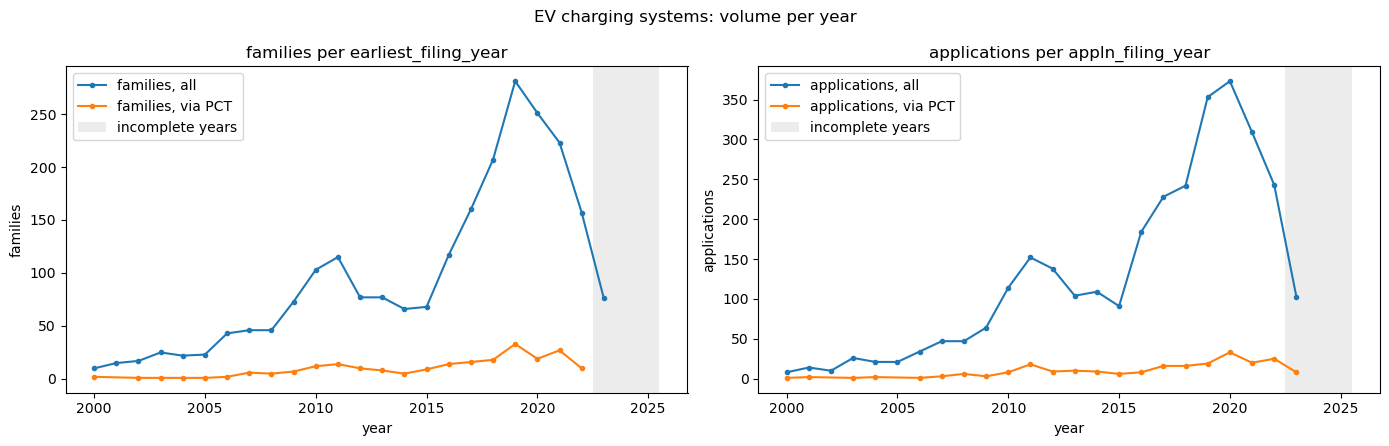

In [31]:
volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.show()


"""
pour l'analyse globale des graphe , on le fera apres avoir utiliser les bon code cpc et etre passe en prod
"""

In [ ]:
#is the sector growing compare with the growth of all patent ?
#If the sector grows by +150% while all patents grow by +60%, the sector is gaining weight in technology. 
#If it grows by +20% while all patents grow by +60%, it is growing, but less than patenting overall. Incomplete years are excluded.

In [32]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

growth.style.format({f"count in {start}": "{:,.0f}", f"count in {end}": "{:,.0f}",
                     f"growth {start}-{end} (%)": "{:+.1f}%"})

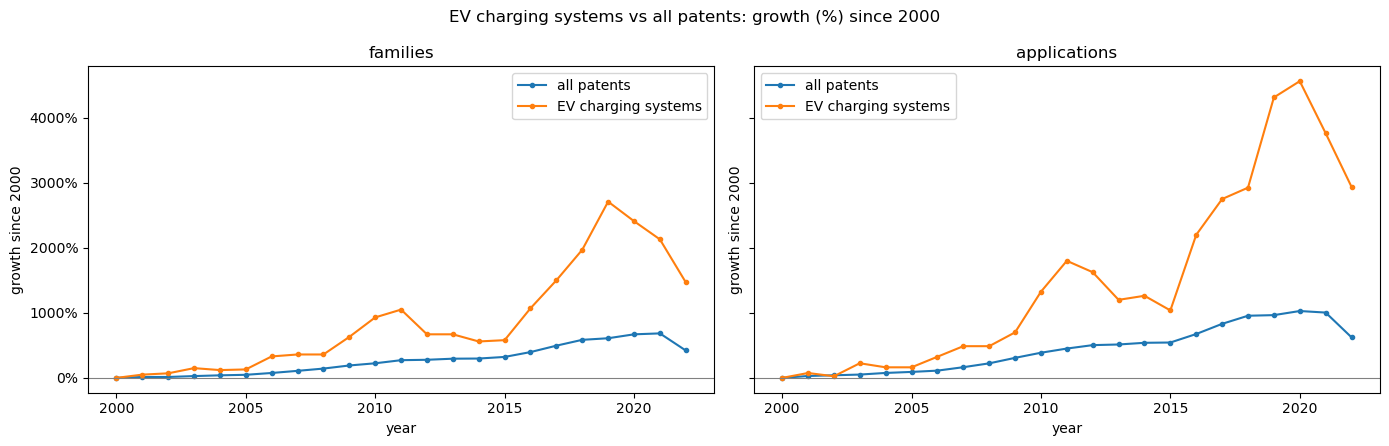

In [33]:
# Growth (%) of each year with respect to the first year: sector vs all patents
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#here we answer the question : 
#- whichntechnologies make up the field ?
#- which classes dominate ?
#- how the mix is shifting?

In [34]:
cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
cpc_pooled = pd.concat([pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
                        for lvl in LEVELS], ignore_index=True)

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)
cpc_shares["definition (fill in from the CPC scheme)"] = ""   # deck table: add the official titles
cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

level,family,application,definition (fill in from the CPC scheme)
subclass,,,
Y02T,27.0%,24.5%,
B60L,18.2%,17.1%,
H02J,9.5%,9.8%,
Y02E,7.5%,8.2%,
Y04S,5.0%,5.5%,
G06F,2.9%,2.4%,
H01M,1.9%,1.9%,
Y02B,1.7%,2.0%,
F03D,1.6%,1.9%,


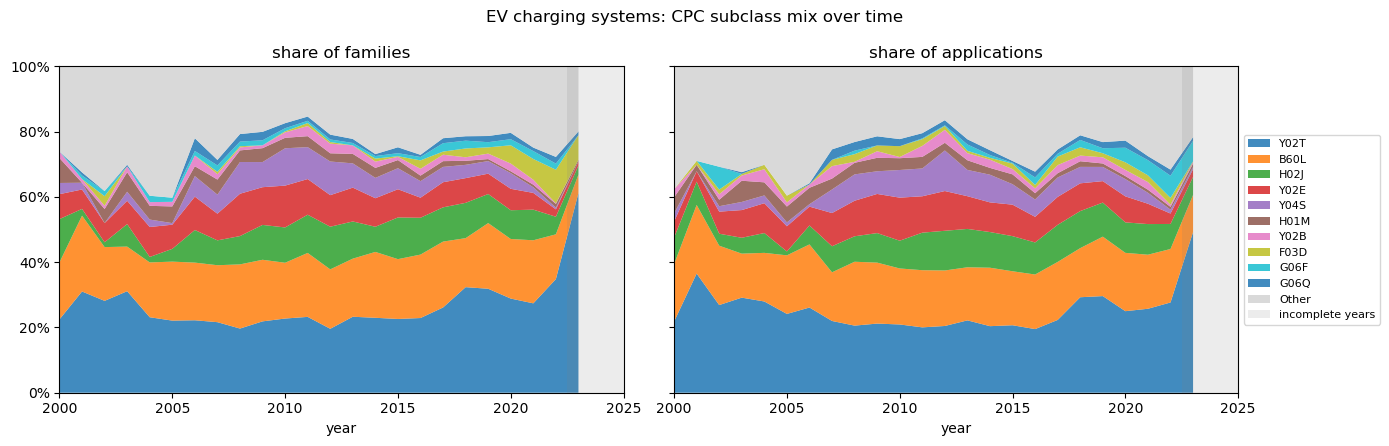

In [35]:
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
#wipo technoloy fields 

In [36]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Mechanical engineering,47.0%,45.7%
Electrical engineering,44.7%,45.9%
Instruments,6.8%,6.8%
Other fields,0.9%,1.0%
Chemistry,0.6%,0.7%
Total,100.0%,100.0%


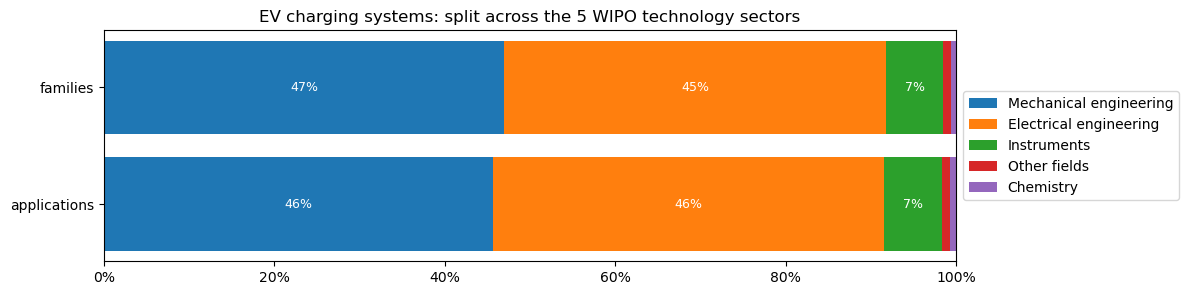

In [37]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

In [38]:
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

level,family,application
techn_field,,
Transport,41.0%,39.5%
"Electrical machinery, apparatus, energy",31.5%,33.4%
Computer technology,8.8%,7.2%
"Engines, pumps, turbines",4.5%,4.6%
Measurement,3.9%,3.3%
Control,2.8%,3.4%
IT methods for management,2.7%,3.3%
Civil engineering,0.6%,0.6%
Digital communication,0.6%,1.0%


In [ ]:
#geography : here we answer the following question 
#- where is it happening?

In [39]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

Share of the sector's applications filed at the IP5: 85.4%


,applications
office,
US,43.9%
CN,30.7%
WO,7.4%
EP,4.6%
KR,3.3%
JP,2.9%
Other,7.2%
Total,100.0%


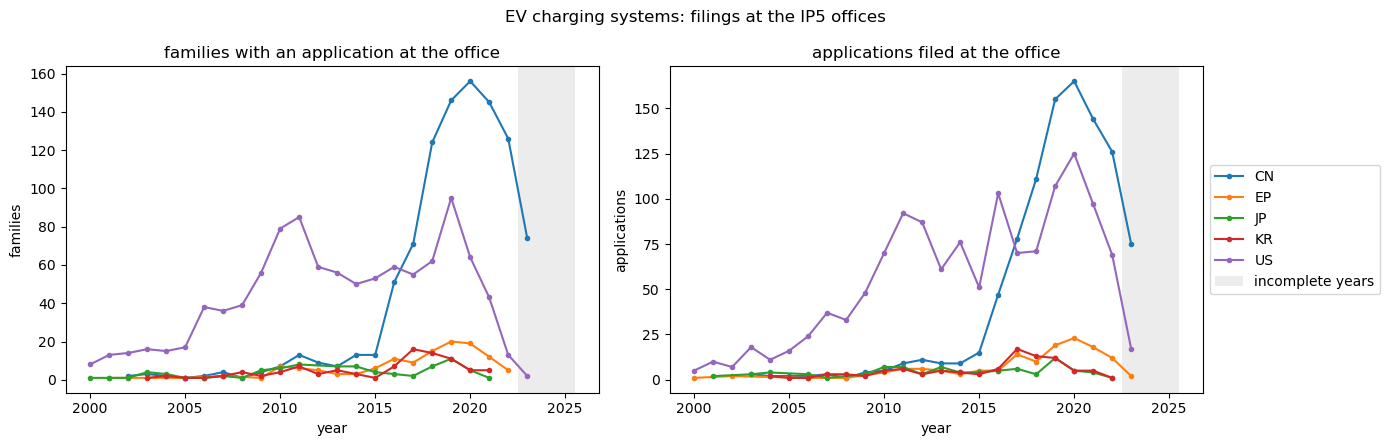

In [40]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [41]:
countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

##PS: watch out for missing values!

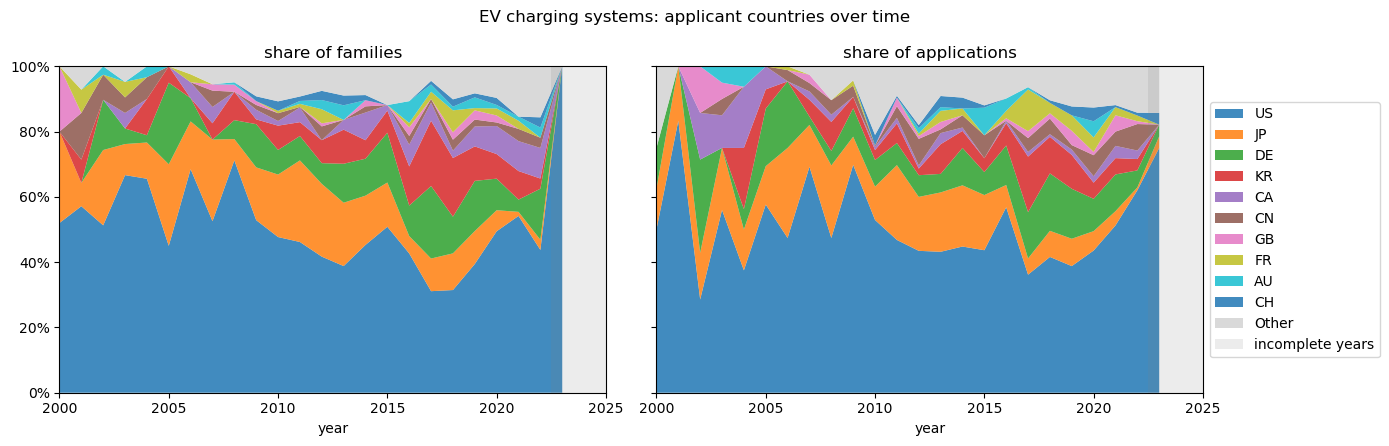

In [42]:
ig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [ ]:
"""
so we need
Appropriability: compare the sector with other evidence on patents vs secrecy (you can look at academic papers on Google scholar)
ce que je dois faire exactement : 

1-Partir de tes données de brevets : Observe ce que montrent tes propres statistiques sur le secteur (par exemple le volume et la croissance des 
brevets sur les systèmes de recharge pour véhicules électriques / B60L 53/00, ainsi que la part hardware vs logiciel/procédés).

2-Consulter Google Scholar pour les repères théoriques : Cherche les études de référence sur l'appropriabilité 
(notamment Levin et al., 1987 et Cohen, Nelson & Walsh, 2000) ainsi que des articles récents appliqués à ton domaine 
("appropriability" "electric vehicle" patents secrecy ou mots-clés équivalents).

3-Poser le consensus de la littérature : Rappelle qu'en général, les entreprises préfèrent le secret industriel et 
l'avance sur le marché (lead time) plutôt que les brevets, sauf dans certains secteurs très spécifiques (comme la pharmacie).

4-Comparer ton secteur à cette référence : Explique pourquoi ton secteur suit ou s'écarte de cette tendance générale — par exemple :

Brevets (patents) : très utilisés quand l'innovation est visible/facile à désassembler (reverse engineering) ou liée à des standards techniques.

Secret (secrecy) : privilégié pour les procédés de fabrication internes, les algorithmes/logiciels ou quand le rythme d'innovation rend la publication d'un brevet peu protectrice.

5-Conclure sur l'arbitrage dans ton domaine : Résume en quelques phrases si ton secteur repose plutôt sur la brevetabilité ou sur le 
secret (ou un mix selon le type d'innovation).
"""